# 🔮 03. Fill Level Forecasting & Demand Prediction
### PreZero / Fillinq Challenge: Predictive Dispatch Intelligence

This notebook forecasts future container fill levels, volume ($m^3$), and weight ($kg$) based on:
$$\\widehat{\\text{Fill}}_i(t + \\Delta t) = \\min(110\\%, \\text{CurrentFill}_i + v_i \\times \\Delta t \\times S_{\\text{holiday}})$$
Containers are classified into **Urgent** ($\\ge 80\\%$) and **Opportunistic** ($60\\% - 79\\%$) stops.
Outputs are saved to `data/predicted_demands.csv` for the Gurobi routing optimizer.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.predictor import predict_container_demands

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (13, 5)

print("Predictor module ready.")


Predictor module ready.


---
## 📥 1. Load Clustered Container Profiles


In [2]:
cluster_path = os.path.join("data", "container_clusters.csv")
if os.path.exists(cluster_path):
    profiles = pd.read_csv(cluster_path)
else:
    from src.data_loader import load_and_clean_data
    from src.clustering import extract_container_profiles, cluster_containers
    df = load_and_clean_data()
    p = extract_container_profiles(df, material_filter='white')
    profiles, _ = cluster_containers(p)

print(f"Loaded {len(profiles)} container profiles.")
display(profiles[['Location_id', 'tier', 'current_fill_perc', 'daily_fill_velocity']].head(5))


Loaded 448 container profiles.


,Location_id,tier,current_fill_perc,daily_fill_velocity
0,0004c095-29ec-4894-81a8-05f3a7a55650,Tier 1: Critical / Chronic High-Volume,20.0,0.147059
1,0058ed93-88f5-4c25-8746-2e5ee87e5559,Tier 3: Moderate Regular,80.0,1.428571
2,009c98f3-c93a-4d55-abfe-79f7acf2a0ff,Tier 2: Steady High-Demand,80.0,0.241871
3,00e9e2cf-b6f7-4872-908b-fcf4c35f388a,Tier 2: Steady High-Demand,100.0,0.333333
4,01371af2-75b4-4b9a-9e74-be20129483d5,Tier 3: Moderate Regular,20.0,1.724138


---
## 🔮 2. Dynamic Forecasting & Urgency Classification
Simulate dispatch planning for a **2-day lookahead** with standard and holiday scenarios:
* Container Volume: $2.5\text{ m}^3$
* Glass Density: $380\text{ kg/m}^3$


In [3]:
# Forecast 2 days into the future
demands = predict_container_demands(
    profiles_df=profiles,
    days_ahead=2,
    holiday_multiplier=1.20,  # +20% surge during holiday periods
    container_volume_m3=2.5,
    glass_density_kg_m3=380.0
)

urgency_dist = demands['urgency_status'].value_counts()
print("=" * 60)
print("          DISPATCH URGENCY CLASSIFICATION (2-DAY FORECAST)")
print("=" * 60)
display(pd.DataFrame({'Count': urgency_dist, 'Percentage (%)': (urgency_dist/len(demands)*100).round(1)}))


          DISPATCH URGENCY CLASSIFICATION (2-DAY FORECAST)


,Count,Percentage (%)
urgency_status,,
Urgent (>=80%),265,59.2
Opportunistic (60-79%),97,21.7
Safe (<60%),86,19.2


---
## 📊 3. Urgency and Demand Distribution


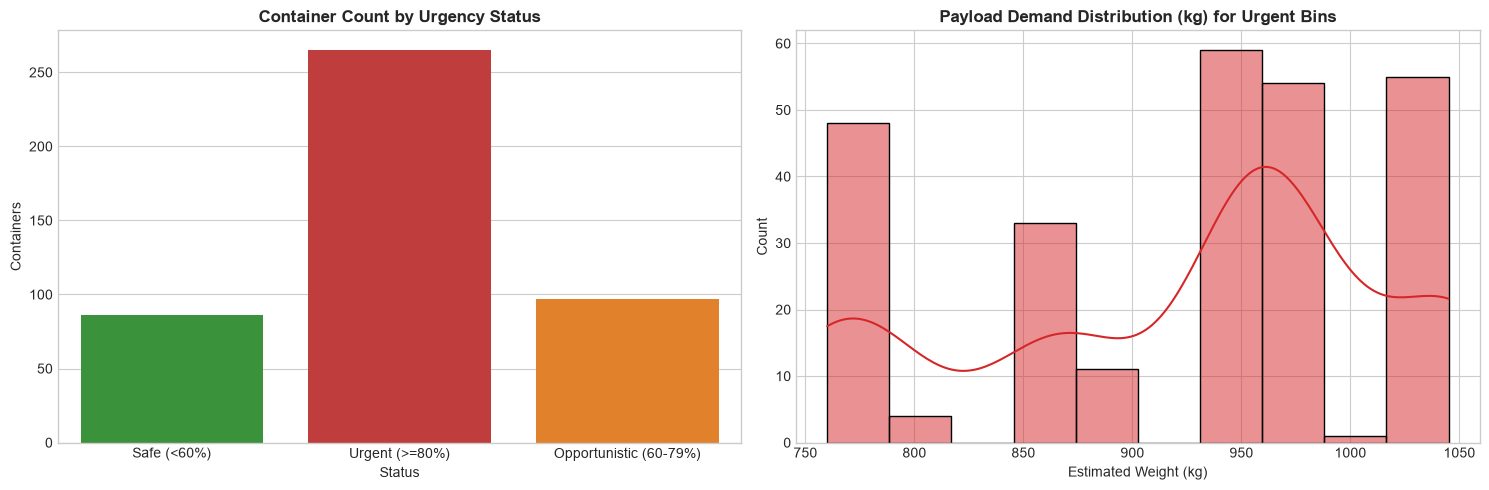

Total Urgent Collection Demand: 645.6 m³ | 245.31 metric tons


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

status_colors = {'Urgent (>=80%)': '#d62728', 'Opportunistic (60-79%)': '#ff7f0e', 'Safe (<60%)': '#2ca02c'}
sns.countplot(data=demands, x='urgency_status', palette=status_colors, ax=axes[0])
axes[0].set_title("Container Count by Urgency Status", fontweight='bold')
axes[0].set_xlabel("Status")
axes[0].set_ylabel("Containers")

# Payload demand distribution for urgent bins
urgent_demands = demands[demands['urgency_status'] == 'Urgent (>=80%)']
sns.histplot(urgent_demands['demand_weight_kg'], kde=True, color='#d62728', ax=axes[1])
axes[1].set_title("Payload Demand Distribution (kg) for Urgent Bins", fontweight='bold')
axes[1].set_xlabel("Estimated Weight (kg)")

plt.tight_layout()
plt.show()

print(f"Total Urgent Collection Demand: {urgent_demands['demand_volume_m3'].sum():.1f} m³ | {urgent_demands['demand_weight_kg'].sum()/1000:.2f} metric tons")


---
## 💾 4. Save Predicted Demands for Optimization


In [5]:
output_path = os.path.join("data", "predicted_demands.csv")
demands.to_csv(output_path, index=False)
print(f"Predicted demands saved to: {output_path}")


Predicted demands saved to: data\predicted_demands.csv
